### 04b. Analysis by Agency, TF-IDF and Visualizations

#### Read-In Data and Load Packages

In [2]:
import numpy as np
import pandas as pd               
import plotnine
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
import re


In [3]:
df_agency = pd.read_csv("../data/fr_rules_labels_metadata.csv")

In [10]:
df_agency["agency"].value_counts()

agency
Health and Human Services Department        65
Commerce Department                         28
Homeland Security Department                16
Education Department                        12
Environmental Protection Agency             12
Consumer Financial Protection Bureau        11
Transportation Department                   10
Securities and Exchange Commission           9
Federal Communications Commission            8
Energy Department                            7
Treasury Department                          7
Labor Department                             6
Library of Congress                          3
Personnel Management Office                  3
Justice Department                           3
Housing and Urban Development Department     3
Federal Trade Commission                     3
Interior Department                          3
Defense Department                           2
Small Business Administration                2
Nuclear Regulatory Commission                2
Federa

In [14]:
top_3 = ["Health and Human Services Department", "Commerce Department", "Homeland Security Department"]

top3_agency = df_agency[df_agency["agency"].isin(top_3)]

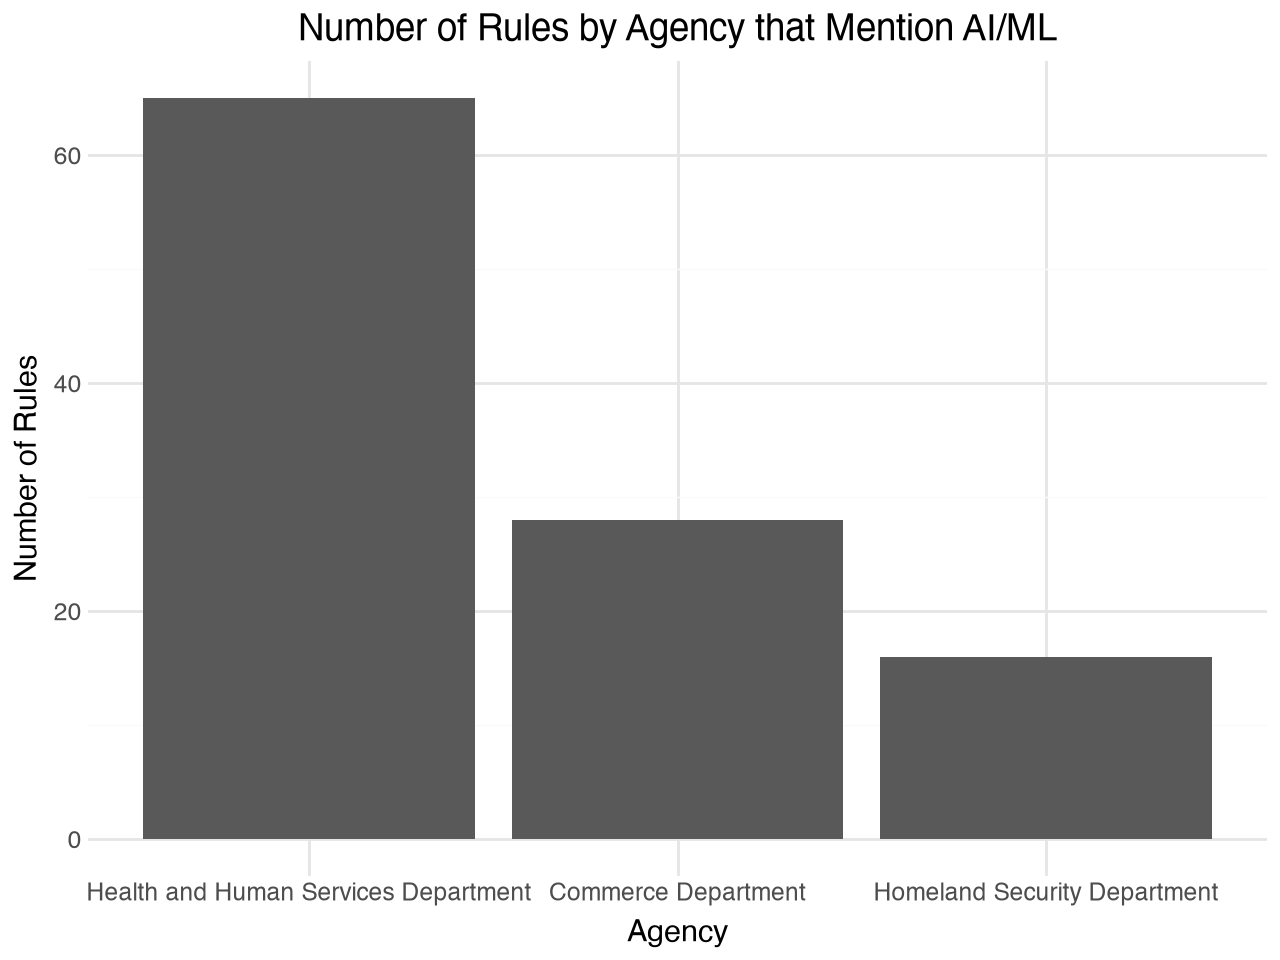

In [18]:
top3_agency_plot = top3_agency.copy()
top3_agency_plot['agency'] = pd.Categorical(top3_agency_plot['agency'], categories=top_3, ordered=True)
plot1 = (plotnine.ggplot(top3_agency_plot, plotnine.aes(x='agency'))
               + plotnine.geom_bar(position='dodge')
               + plotnine.labs(title='Number of Rules by Agency that Mention AI/ML',
                        x='Agency',
                        y='Number of Rules')
                + plotnine.theme(axis_text_x=plotnine.element_text(rotation=45, hjust=1))
                + plotnine.theme_minimal())

plot1

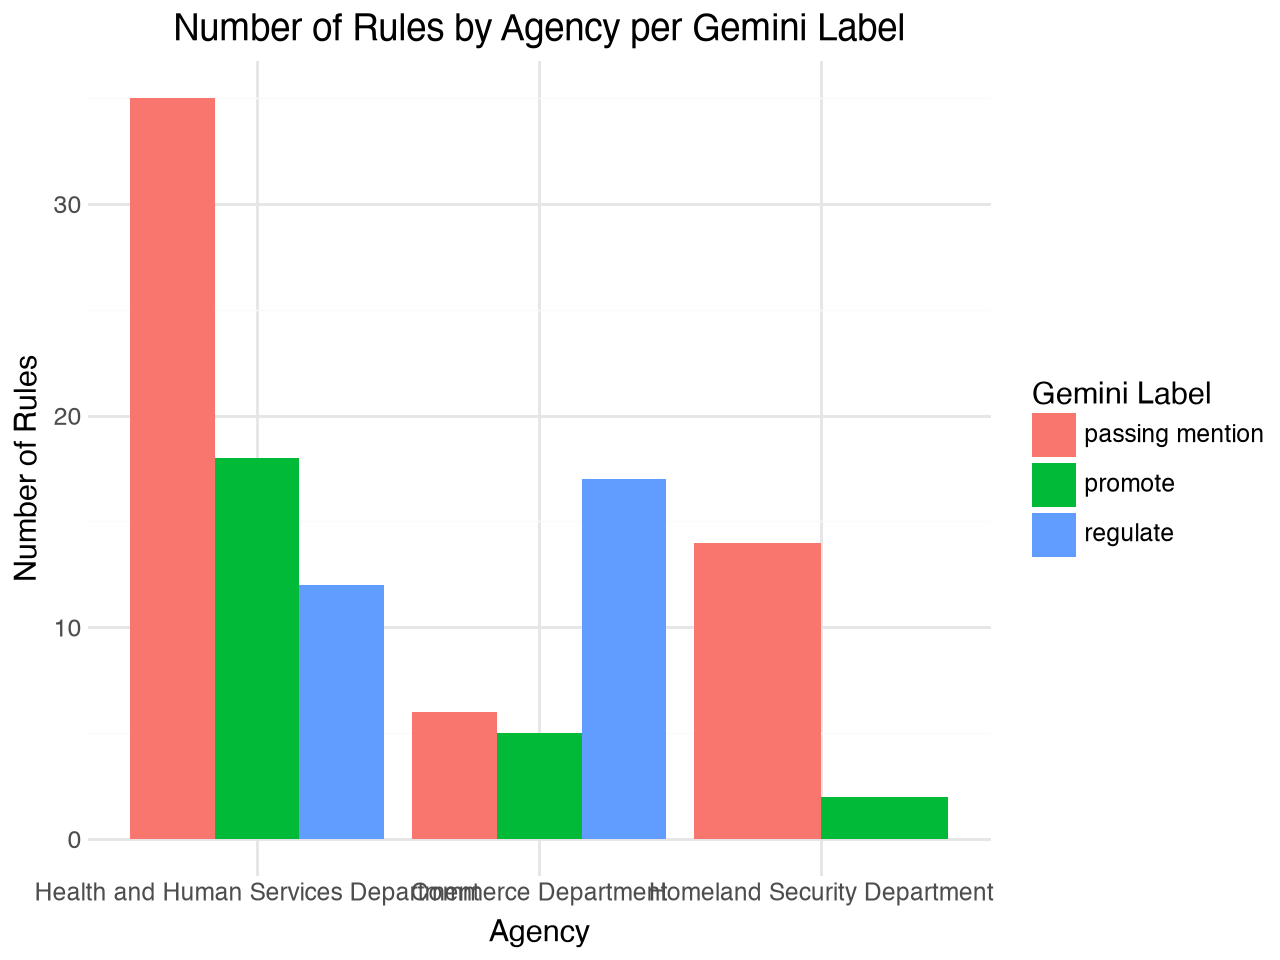

In [19]:
plot2 = (plotnine.ggplot(top3_agency_plot, plotnine.aes(x='agency', fill='gemini_label'))
               + plotnine.geom_bar(position='dodge')
               + plotnine.labs(title='Number of Rules by Agency per Gemini Label',
                        x='Agency',
                        y='Number of Rules',
                        fill ='Gemini Label')
                + plotnine.theme(axis_text_x=plotnine.element_text(rotation=45, hjust=1))
                + plotnine.theme_minimal())

plot2

In [20]:
top3_agency_matched = top3_agency_plot.copy()
top3_agency_matched[ 'matched_artificial_intelligence' ] = top3_agency_matched[ 'matched_terms' ].str.contains('artificial intelligence', case=False, na=False)
top3_agency_matched[ 'matched_machine_learning' ] = top3_agency_matched[ 'matched_terms' ].str.contains('machine learning', case=False, na=False)
top3_agency_matched[ 'matched_automated_decision' ] = top3_agency_matched[ 'matched_terms' ].str.contains('automated decision', case=False, na=False)
top3_agency_matched[ 'matched_deep_learning' ] = top3_agency_matched[ 'matched_terms' ].str.contains('deep learning', case=False, na=False)
top3_agency_matched[ 'matched_large_language_model' ] = top3_agency_matched[ 'matched_terms' ].str.contains('large language model', case=False, na=False)  

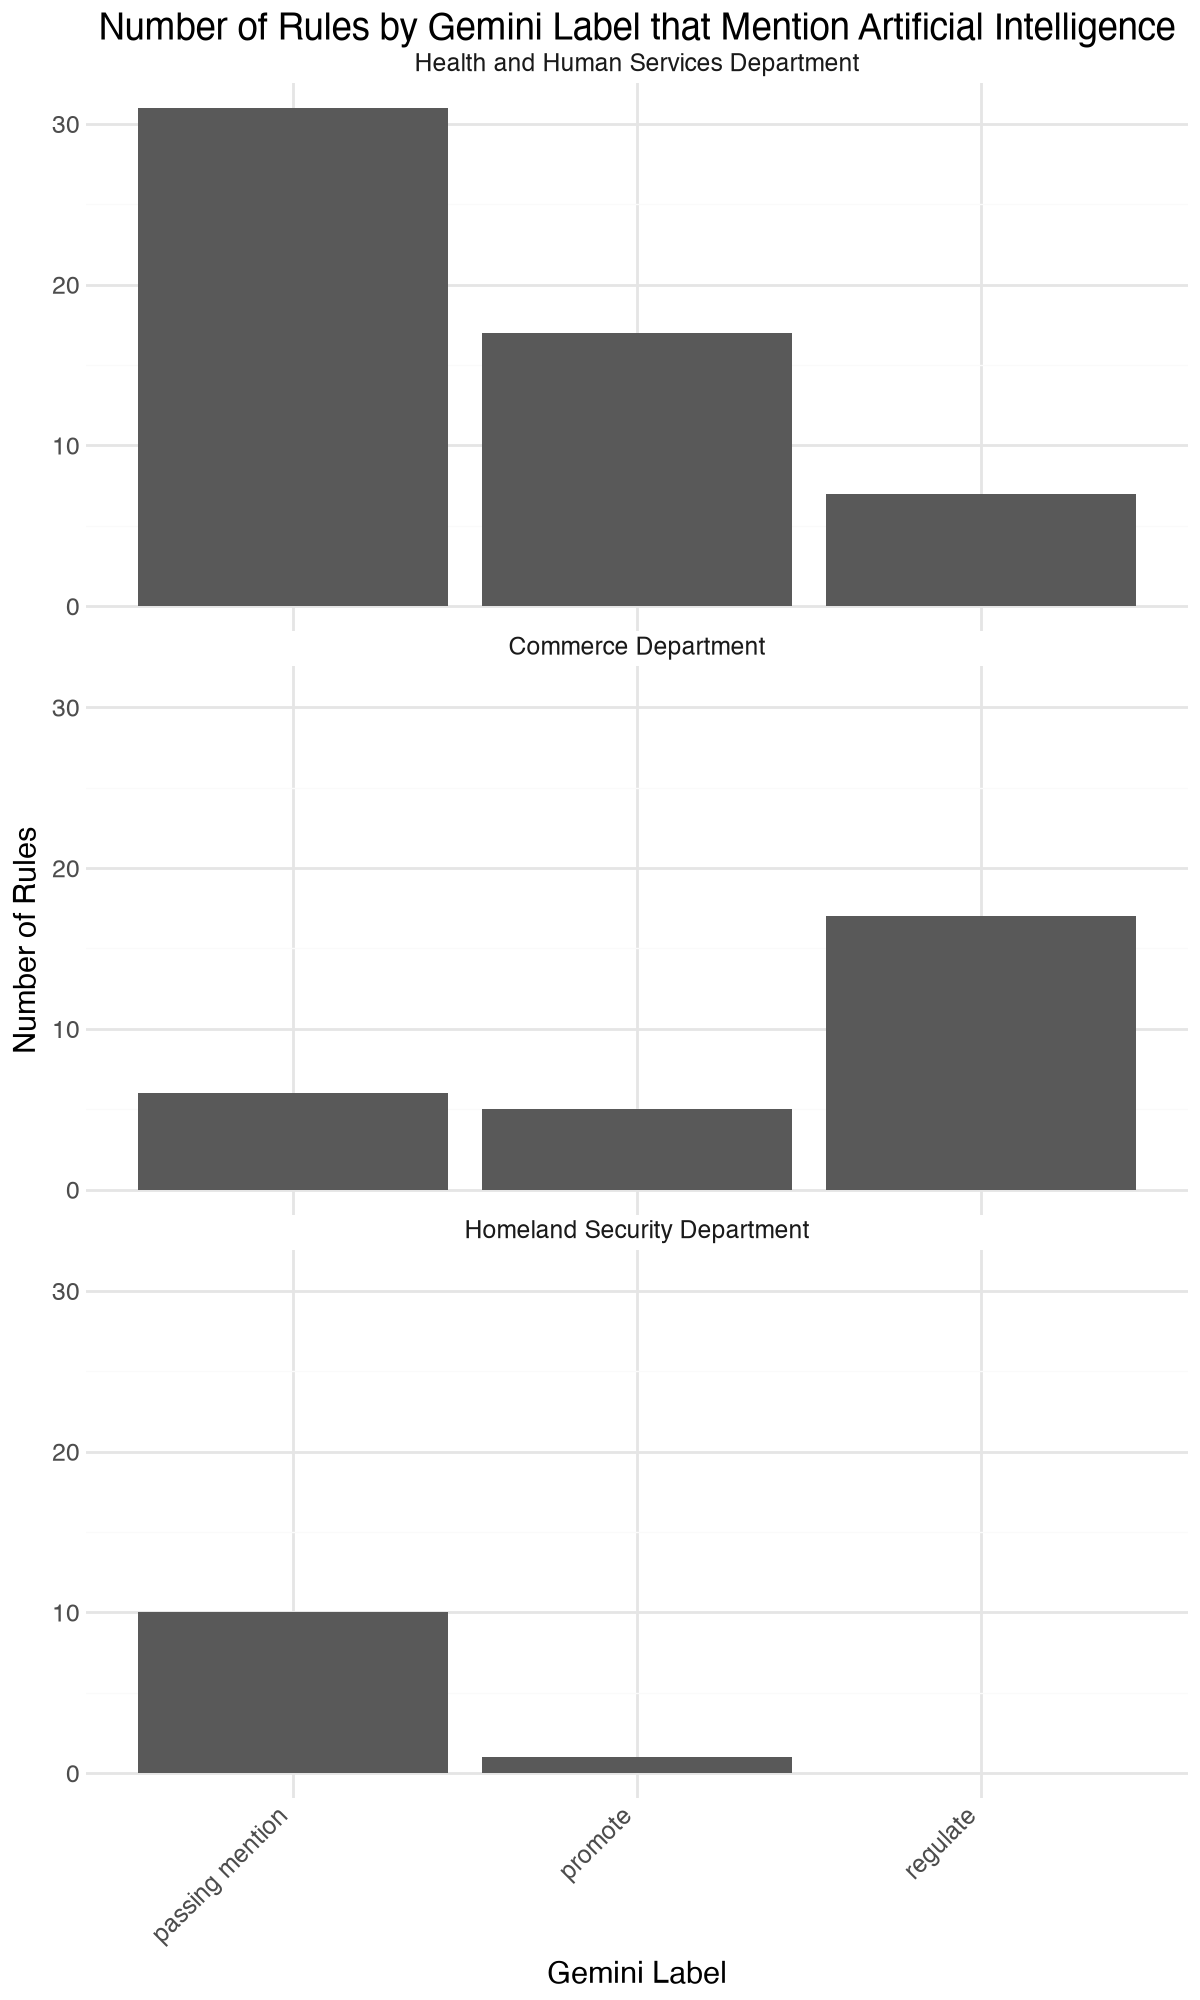

In [22]:
df_ai_true = top3_agency_matched[top3_agency_matched['matched_artificial_intelligence'] == True]
plot3a = (plotnine.ggplot(df_ai_true, plotnine.aes(x='gemini_label'))
               + plotnine.geom_bar()  # Single clean color instead of a legend
               + plotnine.labs(title='Number of Rules by Gemini Label that Mention Artificial Intelligence', x='Gemini Label', y='Number of Rules')
                + plotnine.theme_minimal()
                + plotnine.theme(axis_text_x=plotnine.element_text(rotation=45, hjust=1), figure_size=(6, 10))
                + plotnine.facet_wrap('~agency', ncol=1)
)
plot3a


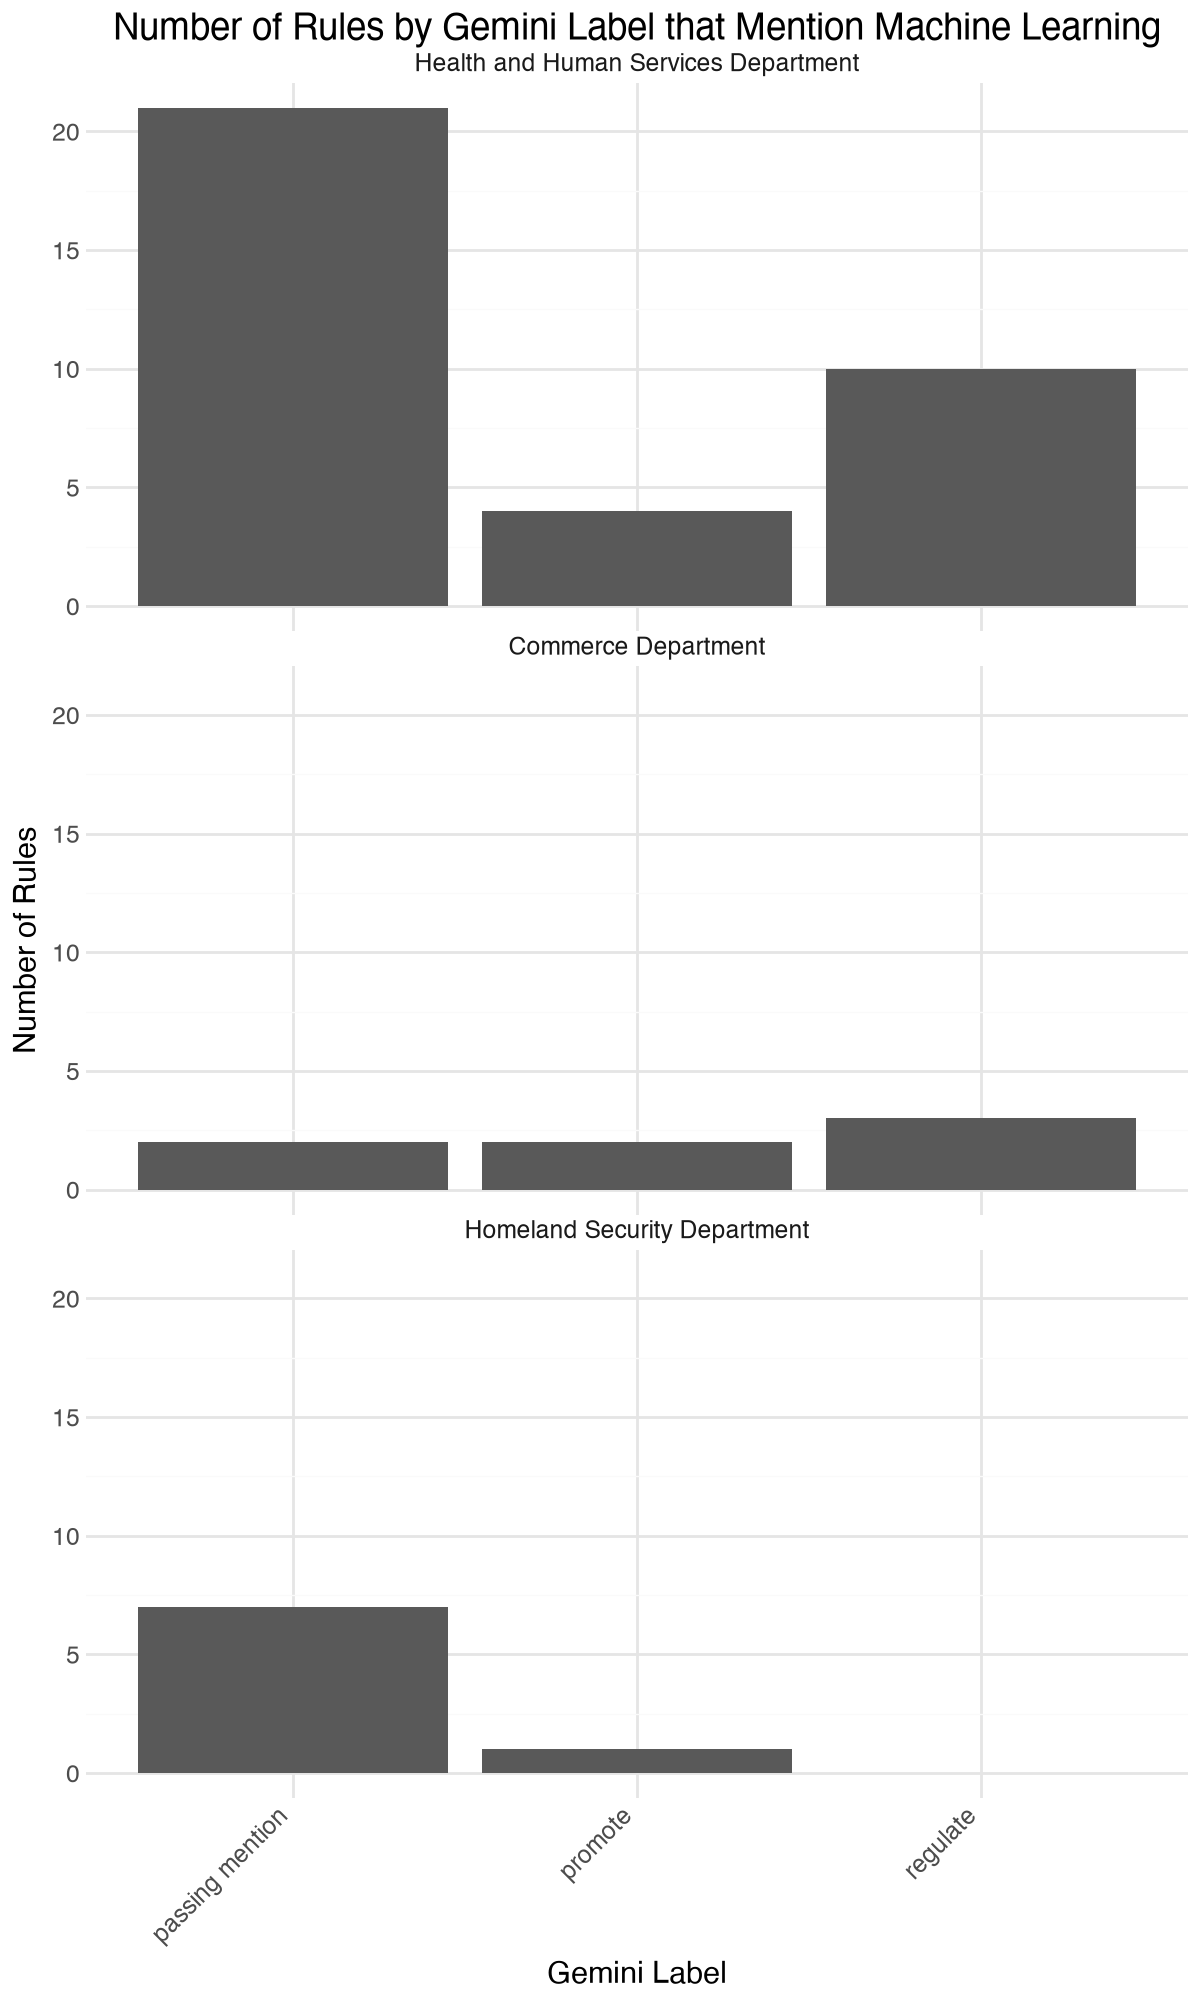

In [23]:
df_ml_true = top3_agency_matched[top3_agency_matched['matched_machine_learning'] == True]
plot3b = (plotnine.ggplot(df_ml_true, plotnine.aes(x='gemini_label'))
               + plotnine.geom_bar()  # Single clean color instead of a legend
               + plotnine.labs(title='Number of Rules by Gemini Label that Mention Machine Learning', x='Gemini Label', y='Number of Rules')
                + plotnine.theme_minimal()
                + plotnine.theme(axis_text_x=plotnine.element_text(rotation=45, hjust=1), figure_size=(6, 10))
                + plotnine.facet_wrap('~agency', ncol=1)
)
plot3b


### TF-IDF BY AGENCY

In [ ]:
, "Commerce Department", "Homeland Security Department"

In [28]:
#functions from HW4
def clean_post(text):
    """Lowercase the text, remove most punctuation, and tidy up spaces."""
    lowered = str(text).lower()
    # Replace anything that isn't a-z, 0-9, a space, an apostrophe, or a hyphen with a space.
    no_punctuation = re.sub(r"[^a-z0-9\s'-]", " ", lowered)
    # Turn runs of spaces into a single space, and trim both ends.
    return re.sub(r"\s+", " ", no_punctuation).strip()

def compare_groups(vectorizer, matrix, mask_a, mask_b, n=15):
    """Return the words whose average score differs most between two groups of rows."""
    average_a = np.asarray(matrix[mask_a].mean(axis=0)).ravel()
    average_b = np.asarray(matrix[mask_b].mean(axis=0)).ravel()
    difference = pd.DataFrame({
        "term": vectorizer.get_feature_names_out(),
        "difference": average_a - average_b,
    }).sort_values("difference", ascending=False)
    return pd.DataFrame({
        "leans_a": difference["term"].head(n).to_numpy(),
        "leans_b": difference["term"].tail(n)[::-1].to_numpy(),
    })

custom_stop_words = list(ENGLISH_STOP_WORDS | {"2019", "2020", "2021", "2022", "2023", "2024", "2025", "2026", "al", "et", 'https'})
project_vectorizer = TfidfVectorizer(stop_words=custom_stop_words, min_df=5)
df_agency["clean_text"] = df_agency["passages"].apply(clean_post)
project_matrix = project_vectorizer.fit_transform(df_agency["clean_text"])

In [25]:
hhs = (df_agency["agency"] == "Health and Human Services Department").to_numpy()
allother_hhs = (df_agency["administration"] != "Health and Human Services Department").to_numpy()
label_terms_hhs = compare_groups(project_vectorizer, project_matrix, hhs, allother_hhs, n=15)
label_terms_hhs.head(15)

,leans_a,leans_b
0,health,security
1,cms,advanced
2,device,critical
3,cpt,national
4,code,energy
5,fda,states
6,payment,united
7,software,information
8,clinical,computing
9,applicant,dhs


In [29]:
commerce = (df_agency["agency"] == "Commerce Department").to_numpy()
allother_commerce = (df_agency["agency"] != "Commerce Department").to_numpy()
label_terms_commerce = compare_groups(project_vectorizer, project_matrix, commerce, allother_commerce, n=15)
label_terms_commerce.head(15)

,leans_a,leans_b
0,advanced,data
1,items,commenters
2,military,proposed
3,entities,commenter
4,bis,comments
5,computing,algorithms
6,ear,based
7,security,code
8,license,available
9,entity,stated


In [30]:
dhs = (df_agency["agency"] == "Homeland Security Department").to_numpy()
allother_dhs = (df_agency["administration"] != "Homeland Security Department").to_numpy()
label_terms_dhs = compare_groups(project_vectorizer, project_matrix, dhs, allother_dhs, n=15)
label_terms_dhs.head(15)

,leans_a,leans_b
0,dhs,department
1,cybersecurity,available
2,united,health
3,states,agency
4,workers,service
5,immigration,device
6,fraud,cms
7,rule,cpt
8,records,items
9,companies,costs
